# First-level GLM bootstrap demo

This notebook demonstrates first-level residual-shift bootstrapping with a fixed **30-second local window**. The window remains configurable through `Statistics_Bootstrapping.options["shift_window_seconds"]`; 30 seconds is the default supported by the real-data validation. Each example runs raw intensity through optical density, MBLL, resampling, and then either AR-IRLS or OLS GLM. Bootstrap inference is attached directly after each GLM. This notebook is limited to per-recording first-level inference; group-level methods are future work.

In [1]:
import copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from pyBrainAnalyzIR.dataclasses.dataset import DataSet
from pyBrainAnalyzIR.pipelines.default_pipelines import default_pipelines
from pyBrainAnalyzIR.pipelines.modules.nonparametric_statistics import Statistics_Bootstrapping
from pyBrainAnalyzIR.testing.simulations.simData import ARnoise, Data as add_simulated_task

rng = np.random.default_rng(1901)
time = np.arange(0., 180., .25)  # three minutes at 4 Hz
stim = pd.DataFrame({
    'onset': [15., 45., 75., 105., 135., 165.],
    'duration': 10.,
    'value': 1.,
    'trial_type': 'task',
})
amplitudes = np.zeros((4, 2))
amplitudes[[0, 3], :] = .8  # two active channels; two channels remain null

recordings = []
truth = []
for subject, seed in enumerate((1902, 1903), start=1):
    noise = ARnoise(t=time, random_seed=rng, registered3D=True)
    noise['amp'] = noise['amp'].isel(channel=slice(0, 4))
    recording, active = add_simulated_task(
        noise=noise,
        stim=stim,
        snr=1.5,
        amplitudes={'task': amplitudes},
        random_seed=seed,
    )
    recording.meta_data['subject'] = f'Subject {subject}'
    recordings.append(recording)
    truth.append(active)

print(f'{len(recordings)} independent subjects; {recordings[0]["amp"].sizes["channel"]} channels each')
display(truth[0].to_dataframe(name='InjectedActivation').reset_index())

2 independent subjects; 4 channels each


,channel,chromo,InjectedActivation
0,S1D1,HbO,True
1,S1D1,HbR,True
2,S2D1,HbO,False
3,S2D1,HbR,False
4,S2D2,HbO,False
5,S2D2,HbR,False
6,S3D2,HbO,True
7,S3D2,HbR,True


## Synthetic example

Two simulated raw-intensity recordings include AR noise, a known task design, and a mixture of active and null channels. Both GLM noise models use the same preprocessing and 30-second bootstrap settings. The small iteration count is for a runnable demonstration, not final tail-probability estimation.

In [2]:
bootstrap_tables = []
iterations = 25

for noise_model in ('ar_irls', 'ols'):
    pipeline = default_pipelines.first_level_analysis.pipeline()
    pipeline.set_all_options({
        'noise_model': noise_model,
        'ar_order': 50,
        'max_jobs': 1,
        'verbose': False,
    })
    bootstrap = Statistics_Bootstrapping(pipeline)
    bootstrap.options['iterations'] = iterations
    bootstrap.options['shift_window_seconds'] = 30.
    bootstrap.options['alpha'] = .05
    bootstrap.options['random_seed'] = 1910

    results = DataSet(copy.deepcopy(recordings))
    bootstrap.run(results)
    for subject_index, recording in enumerate(results.dataset):
        table = recording.aux_obj['bootstrap'].table.copy()
        table['Subject'] = recording.meta_data['subject']
        table['Model'] = noise_model
        table['Truth'] = [
            bool(truth[subject_index].sel(channel=row.Channel, chromo=row.Type))
            for row in table.itertuples()
        ]
        bootstrap_tables.append(table)

results_table = pd.concat(bootstrap_tables, ignore_index=True)
display(results_table.sort_values(['Model', 'Subject', 'Channel', 'Type']))

,Channel,Type,Condition,Beta,ParametricP,EmpiricalP,NullMean,NullStd,NullFPR,PowerAtObservedBeta,BootstrapCILower,BootstrapCIUpper,NullThreshold,NullTimecourseVarianceRatio,NullTimecourseVarianceRatioStd,Subject,Model,Truth
0,S1D1,HbO,HRF task,0.337615,3.339717e-27,0.038462,-0.000128,0.034567,0.04,1.00,0.289980,0.402870,0.063199,0.496100,1.744411e-16,Subject 1,ar_irls,True
1,S1D1,HbR,HRF task,-0.231202,3.279638e-29,0.038462,0.000426,0.023498,0.04,1.00,-0.274575,-0.195953,0.038861,0.353309,3.109368e-16,Subject 1,ar_irls,True
2,S2D1,HbO,HRF task,-0.009168,8.031846e-01,0.884615,-0.001193,0.035819,0.04,0.04,-0.074526,0.042696,0.069141,1.001515,6.377746e-16,Subject 1,ar_irls,False
3,S2D1,HbR,HRF task,-0.008278,7.455663e-01,0.653846,0.000282,0.016786,0.04,0.20,-0.040638,0.014924,0.025258,0.999019,3.812394e-16,Subject 1,ar_irls,False
4,S2D2,HbO,HRF task,-0.037698,2.446077e-01,0.115385,0.007874,0.022951,0.04,0.28,-0.069361,0.012813,0.042852,0.989973,2.064637e-16,Subject 1,ar_irls,False
5,S2D2,HbR,HRF task,-0.004811,8.359265e-01,0.769231,-0.006210,0.016239,0.04,0.08,-0.041424,0.018098,0.030191,0.999602,2.113802e-16,Subject 1,ar_irls,False
6,S3D2,HbO,HRF task,0.347765,3.597953e-22,0.038462,-0.012178,0.036848,0.04,1.00,0.269640,0.401006,0.075741,0.584140,1.086847e-16,Subject 1,ar_irls,True
7,S3D2,HbR,HRF task,-0.244255,1.023843e-24,0.038462,0.008000,0.027188,0.04,1.00,-0.280107,-0.194327,0.049638,0.700068,2.593823e-16,Subject 1,ar_irls,True
8,S1D1,HbO,HRF task,0.268663,8.484348e-12,0.038462,0.004388,0.047315,0.04,1.00,0.201257,0.348099,0.074963,0.488767,2.194271e-16,Subject 2,ar_irls,True
9,S1D1,HbR,HRF task,-0.191129,1.934100e-12,0.038462,0.005061,0.032835,0.04,1.00,-0.243011,-0.137420,0.055924,0.373838,1.355010e-16,Subject 2,ar_irls,True


,Model,Null signal count,Parametric null rejection rate,Empirical null rejection rate,Mean bootstrap null FPR,Mean plug-in power on active signals
0,ar_irls,8,0.125,0.125,0.04,1.0
1,ols,8,0.500,0.000,0.04,1.0


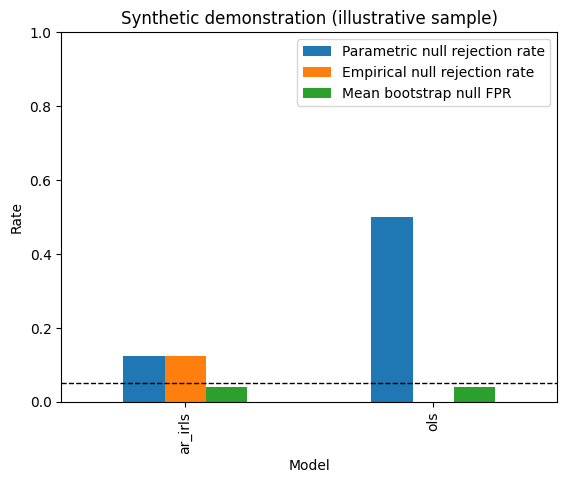

In [3]:
summary = []
for model, group in results_table.groupby('Model'):
    null_channels = group.loc[~group.Truth]
    active_channels = group.loc[group.Truth]
    summary.append({
        'Model': model,
        'Null signal count': len(null_channels),
        'Parametric null rejection rate': (null_channels.ParametricP < .05).mean(),
        'Empirical null rejection rate': (null_channels.EmpiricalP <= .05).mean(),
        'Mean bootstrap null FPR': null_channels.NullFPR.mean(),
        'Mean plug-in power on active signals': active_channels.PowerAtObservedBeta.mean(),
    })
summary_table = pd.DataFrame(summary)
display(summary_table)

ax = summary_table.set_index('Model')[
    ['Parametric null rejection rate', 'Empirical null rejection rate', 'Mean bootstrap null FPR']
].plot.bar(ylim=(0, 1), ylabel='Rate', title='Synthetic demonstration (illustrative sample)')
ax.axhline(.05, color='black', linestyle='--', linewidth=1)
plt.show()

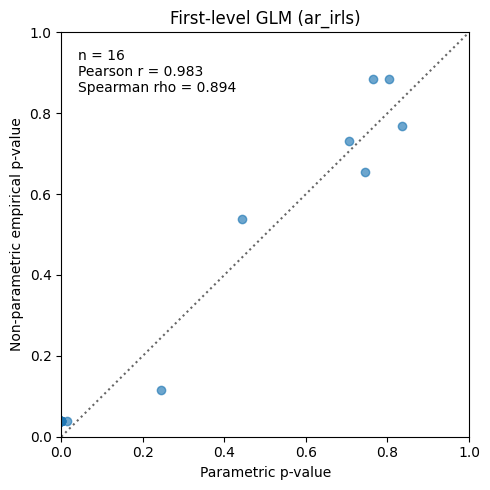

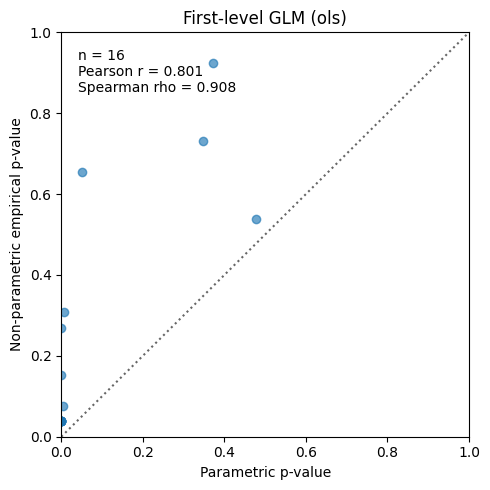

,comparison,n,pearson_r,spearman_rho
0,First-level GLM (ar_irls),16,0.983350,0.893699
1,First-level GLM (ols),16,0.801406,0.907926


In [4]:
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt


def compare_pvalues(table, label):
    """Plot parametric against bootstrap p-values and report correlation."""
    paired = table[['ParametricP', 'EmpiricalP']].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()
    if len(paired) < 2:
        raise ValueError(f'{label}: need at least two finite p-value pairs.')
    pearson = pearsonr(paired['ParametricP'], paired['EmpiricalP']).statistic
    spearman = spearmanr(paired['ParametricP'], paired['EmpiricalP']).statistic
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(paired['ParametricP'], paired['EmpiricalP'], alpha=.65)
    ax.plot([0, 1], [0, 1], linestyle=':', color='0.4')
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Parametric p-value',
           ylabel='Non-parametric empirical p-value', title=label)
    ax.text(.04, .96, f'n = {len(paired)}\nPearson r = {pearson:.3f}\n'
            f'Spearman rho = {spearman:.3f}', transform=ax.transAxes,
            va='top')
    fig.tight_layout()
    plt.show()
    return {'comparison': label, 'n': len(paired),
            'pearson_r': pearson, 'spearman_rho': spearman}


glm_pvalue_correlations = [
    compare_pvalues(results_table[results_table['Model'] == model],
                    f'First-level GLM ({model})')
    for model in results_table['Model'].drop_duplicates()
]
pd.DataFrame(glm_pvalue_correlations)

## NIRx experimental-data example

The next example loads up to two NIRx SNIRF recordings and runs the same raw-intensity → optical density → MBLL → resampling → AR-IRLS/OLS GLM pipelines, each followed by the 30-second bootstrap. It uses only recordings with one event type because that is the current bootstrap module scope. Increase `NIRX_MAX_RECORDINGS` or `BOOTSTRAP_ITERATIONS` for a larger analysis; the latter should be increased for stable tail estimates.

In [5]:
from pathlib import Path

from cedalion.io.snirf import read_snirf

NIRX_ROOT = Path.home() / 'Desktop' / 'OneDrive_1_10-28-2026'
NIRX_MAX_RECORDINGS = 2
BOOTSTRAP_ITERATIONS = 25
KNOWN_HDF5_READ_BLOCKERS = {'4072-pair-v1-mom_001'}

snirf_paths = [
    path for path in sorted(NIRX_ROOT.rglob('*.snirf'))
    if path.stem not in KNOWN_HDF5_READ_BLOCKERS
]
if not snirf_paths:
    raise FileNotFoundError(f'No readable NIRx SNIRF candidates found under {NIRX_ROOT}')

experimental_recordings = []
for path in snirf_paths:
    loaded = list(read_snirf(path))
    eligible = [
        recording for recording in loaded
        if hasattr(recording, 'stim')
        and not recording.stim.empty
        and recording.stim.trial_type.astype(str).nunique() == 1
    ]
    for recording_index, recording in enumerate(eligible):
        recording.meta_data['subject'] = f'{path.stem}:{recording_index}'
        experimental_recordings.append(recording)
        if len(experimental_recordings) >= NIRX_MAX_RECORDINGS:
            break
    if len(experimental_recordings) >= NIRX_MAX_RECORDINGS:
        break

if not experimental_recordings:
    raise ValueError(
        'No selected NIRx recordings had a nonempty stimulus table with exactly one event type.'
    )
print(f'Loaded {len(experimental_recordings)} NIRx recording(s) with one event type.')

Loaded 2 NIRx recording(s) with one event type.


In [6]:
experimental_tables = []
for noise_model in ('ar_irls', 'ols'):
    pipeline = default_pipelines.first_level_analysis.pipeline()
    pipeline.set_all_options({
        'noise_model': noise_model,
        'ar_order': 50,
        'max_jobs': 1,
        'verbose': False,
    })
    bootstrap = Statistics_Bootstrapping(pipeline)
    bootstrap.options['iterations'] = BOOTSTRAP_ITERATIONS
    bootstrap.options['shift_window_seconds'] = 30.
    bootstrap.options['alpha'] = .05
    bootstrap.options['random_seed'] = 1920

    results = DataSet(copy.deepcopy(experimental_recordings))
    bootstrap.run(results)
    for recording in results.dataset:
        table = recording.aux_obj['bootstrap'].table.copy()
        table['Recording'] = recording.meta_data['subject']
        table['Model'] = noise_model
        experimental_tables.append(table)

experimental_results = pd.concat(experimental_tables, ignore_index=True)
display(experimental_results.sort_values(['Model', 'Recording', 'Channel', 'Type']))

/Users/theodorehuppert/VSCode/pyNIRS_toolbox/pyNIRS_toolbox/pyBrainAnalyzIR/math/glm/ar_irls.py:130: RuntimeWarning: Bisquare regression reached 1000 iterations before coefficient convergence.
  coefficients = _robust_fit(
/Users/theodorehuppert/VSCode/pyNIRS_toolbox/pyNIRS_toolbox/pyBrainAnalyzIR/math/glm/ar_irls.py:130: RuntimeWarning: Bisquare regression reached 1000 iterations before coefficient convergence.
  coefficients = _robust_fit(
/Users/theodorehuppert/VSCode/pyNIRS_toolbox/pyNIRS_toolbox/pyBrainAnalyzIR/math/glm/ar_irls.py:130: RuntimeWarning: Bisquare regression reached 1000 iterations before coefficient convergence.
  coefficients = _robust_fit(
/Users/theodorehuppert/VSCode/pyNIRS_toolbox/pyNIRS_toolbox/pyBrainAnalyzIR/math/glm/ar_irls.py:130: RuntimeWarning: Bisquare regression reached 1000 iterations before coefficient convergence.
  coefficients = _robust_fit(
/Users/theodorehuppert/VSCode/pyNIRS_toolbox/pyNIRS_toolbox/pyBrainAnalyzIR/math/glm/ar_irls.py:130: Runtime

,Channel,Type,Condition,Beta,ParametricP,EmpiricalP,NullMean,NullStd,NullFPR,PowerAtObservedBeta,BootstrapCILower,BootstrapCIUpper,NullThreshold,NullTimecourseVarianceRatio,NullTimecourseVarianceRatioStd,Recording,Model
0,S1D1,HbO,HRF 12,-0.047143,6.226175e-01,0.730769,0.072983,0.125259,0.04,0.00,-0.149979,0.243398,0.273898,0.999966,2.980764e-16,4058-pair-v1-baby_001:0,ar_irls
1,S1D1,HbR,HRF 12,-0.035306,4.118502e-01,0.538462,0.028270,0.045205,0.04,0.00,-0.083781,0.068764,0.101171,1.011603,4.577567e-16,4058-pair-v1-baby_001:0,ar_irls
2,S1D2,HbO,HRF 12,-0.083566,9.826370e-02,0.115385,0.018598,0.042015,0.04,0.20,-0.149642,0.001090,0.087871,0.997671,3.633048e-16,4058-pair-v1-baby_001:0,ar_irls
3,S1D2,HbR,HRF 12,-0.020353,5.008607e-01,0.461538,0.015031,0.014185,0.04,0.04,-0.035744,0.015627,0.035210,1.010772,4.104323e-16,4058-pair-v1-baby_001:0,ar_irls
4,S2D1,HbO,HRF 12,-0.001765,9.777506e-01,1.000000,0.010438,0.085902,0.04,0.04,-0.113678,0.177235,0.159598,0.999981,3.023532e-16,4058-pair-v1-baby_001:0,ar_irls
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
131,S6D6,HbR,HRF 12,-0.114243,4.919607e-13,0.038462,-0.046000,0.041924,0.04,0.92,-0.210145,-0.089584,0.093999,0.968921,2.430264e-16,4062-pair-v1-baby_001:0,ols
132,S7D7,HbO,HRF 12,0.036454,9.355560e-01,1.000000,-0.327436,0.688369,0.04,0.00,-1.346772,0.985420,1.377837,0.999996,3.839243e-16,4062-pair-v1-baby_001:0,ols
133,S7D7,HbR,HRF 12,-0.006953,9.728513e-01,1.000000,-0.255483,0.321603,0.04,0.08,-0.667834,0.334279,0.656996,0.999999,2.573946e-16,4062-pair-v1-baby_001:0,ols
134,S8D8,HbO,HRF 12,0.018799,7.740518e-01,0.923077,0.030390,0.175600,0.04,0.08,-0.115974,0.418093,0.395612,0.999950,1.537034e-16,4062-pair-v1-baby_001:0,ols


**Scope and interpretation.** The 30-second window is a pragmatic, data-informed default, not a guarantee of exchangeability or calibrated inference for every recording. Empirical results are per channel and per recording; no group-level inference or multiple-comparison correction is performed. Plug-in power is conditional on the observed effect estimate and can be optimistic. Inspect the recordings and event design before interpreting results.

## First-level resting-state connectivity bootstrap

This example runs one simulated recording through intensity → optical density → MBLL → resampling → resting-state connectivity → bootstrap. The edge-wise null independently circular-shifts each signal within the configurable local window, preserving each signal's within-window marginal series/autocorrelation while breaking contemporaneous inter-signal alignment. It does not preserve the full spatial covariance under the edge null.

In [7]:
from pyBrainAnalyzIR.pipelines.modules.connectivity import resting_state_connectivity
from pyBrainAnalyzIR.pipelines.modules import preproccessing as prep
from pyBrainAnalyzIR.testing.roc.channelROC import PipelineList
from pyBrainAnalyzIR.testing.simulations.simData import simdataset_connectivity

connectivity_data, connectivity_truth = simdataset_connectivity(
    num_files=1, t=np.arange(0., 120., .1), sigma=0, random_seed=1930
)
connectivity_pipeline = PipelineList([
    prep.intensity_opticaldensity,
    prep.mbll,
    prep.resample,
    resting_state_connectivity,
])
connectivity_pipeline.set_all_options({
    'Fs': 2, 'AR': 1000, 'robust': False,
    'short_separation_correction': True,
})
connectivity_bootstrap = Statistics_Bootstrapping(connectivity_pipeline)
connectivity_bootstrap.options['iterations'] = 19
connectivity_bootstrap.options['shift_window_seconds'] = 30.
connectivity_bootstrap.options['random_seed'] = 1931
connectivity_bootstrap.run(connectivity_data)
display(connectivity_data.dataset[0].aux_obj['bootstrap'].table.head())

,Pair,Condition,Channel_to,Type_to,Channel_from,Type_from,Coefficient,ParametricP,EmpiricalP,NullMean,NullThreshold,NullFPR,PowerAtObservedEffect,BootstrapCILower,BootstrapCIUpper
0,sub-001,rest,S2D1,HbO,S1D1,HbO,-0.073422,0.257197,0.20,0.006548,0.089890,0.0,0.526316,-0.142356,0.012625
1,sub-001,rest,S2D2,HbO,S1D1,HbO,0.013326,0.837272,0.90,-0.073005,0.225222,0.0,0.000000,-0.208820,0.081729
2,sub-001,rest,S3D2,HbO,S1D1,HbO,0.039242,0.545185,0.40,0.003859,0.122757,0.0,0.105263,-0.048827,0.128494
3,sub-001,rest,S3D3,HbO,S1D1,HbO,0.054582,0.399905,0.50,0.019053,0.128447,0.0,0.210526,-0.047819,0.167345
4,sub-001,rest,S4D3,HbO,S1D1,HbO,0.085695,0.185809,0.15,-0.022063,0.154055,0.0,0.000000,-0.040843,0.135262


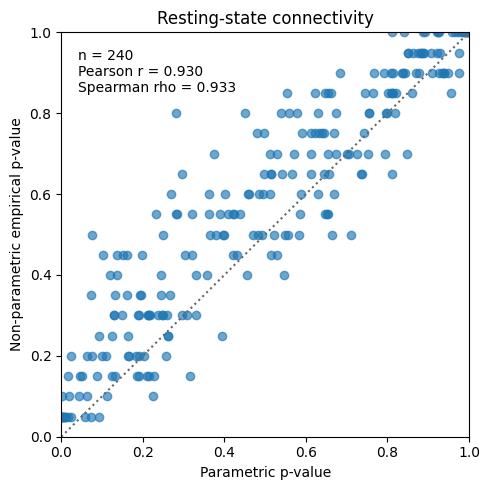

,comparison,n,pearson_r,spearman_rho
0,Resting-state connectivity,240,0.930439,0.933411


In [8]:
connectivity_bootstrap_table = connectivity_data.dataset[0].aux_obj['bootstrap'].table
connectivity_pvalue_correlation = compare_pvalues(
    connectivity_bootstrap_table, 'Resting-state connectivity'
)
pd.DataFrame([connectivity_pvalue_correlation])

## First-level hyperscanning bootstrap

For hyperscanning, each bootstrap replicate circularly shifts one participant relative to the other, applying the same offset to all of that participant's channels. This preserves within-participant spatial relationships and breaks cross-participant timing alignment. The result is a per-dyad edge table, not a group-level model.

In [9]:
from pyBrainAnalyzIR.pipelines.modules.connectivity import hyperscanning
from pyBrainAnalyzIR.pipelines.modules import preproccessing as prep
from pyBrainAnalyzIR.testing.roc.channelROC import PipelineList
from pyBrainAnalyzIR.testing.simulations.simData import simdataset_hyperscanning

hyperscanning_data, hyperscanning_truth = simdataset_hyperscanning(
    num_dyads=1, t=np.arange(0., 120., .1), sigma=0,
    effect_size=0.2, random_seed=1940,
)
hyperscanning_pipeline = PipelineList([
    prep.intensity_opticaldensity,
    prep.mbll,
    prep.resample,
    hyperscanning,
])
hyperscanning_pipeline.set_all_options({
    'Fs': 2, 'AR': 50, 'robust': False,
    'short_separation_correction': True,
    'grouping_variable': 'pair',
})
hyperscanning_bootstrap = Statistics_Bootstrapping(hyperscanning_pipeline)
hyperscanning_bootstrap.options['iterations'] = 250
hyperscanning_bootstrap.options['shift_window_seconds'] = 30.
hyperscanning_bootstrap.options['random_seed'] = 1941
hyperscanning_bootstrap.run(hyperscanning_data)
display(hyperscanning_data.dataset[0].aux_obj['bootstrap'].table.head())

Computing connectivity for pair=dyad-001


,Pair,Subject_to,Channel_to,Type_to,Subject_from,Channel_from,Type_from,Condition,Coefficient,ParametricP,EmpiricalP,NullMean,NullThreshold,NullFPR,PowerAtObservedEffect,BootstrapCILower,BootstrapCIUpper
0,dyad-001,dyad-001-B,S1D1,HbO,dyad-001-A,S1D1,HbO,rest,-0.044830,0.490343,0.454183,-0.021117,0.123301,0.048,0.184,-0.179224,0.052738
1,dyad-001,dyad-001-B,S1D1,HbO,dyad-001-A,S2D1,HbO,rest,-0.022807,0.725754,0.697211,-0.005896,0.106533,0.048,0.076,-0.125786,0.084960
2,dyad-001,dyad-001-B,S1D1,HbO,dyad-001-A,S2D2,HbO,rest,-0.005323,0.934755,0.948207,-0.012568,0.123290,0.048,0.068,-0.135715,0.091684
3,dyad-001,dyad-001-B,S1D1,HbO,dyad-001-A,S3D2,HbO,rest,0.039890,0.539418,0.589641,0.021178,0.128411,0.048,0.148,-0.065288,0.176281
4,dyad-001,dyad-001-B,S1D1,HbO,dyad-001-A,S3D3,HbO,rest,-0.037906,0.559796,0.605578,-0.037245,0.143494,0.048,0.148,-0.189988,0.035283


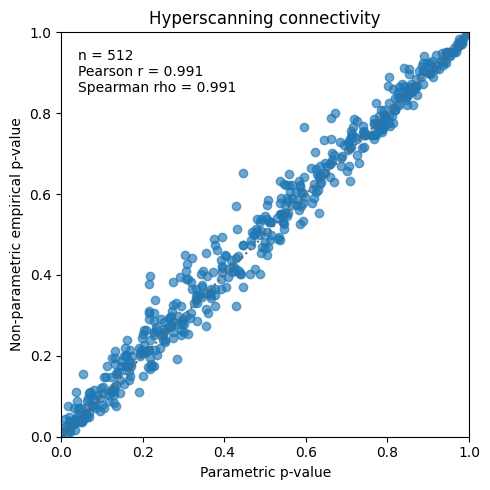

,comparison,n,pearson_r,spearman_rho
0,Hyperscanning connectivity,512,0.99057,0.990527


In [10]:
hyperscanning_bootstrap_table = hyperscanning_data.dataset[0].aux_obj['bootstrap'].table
hyperscanning_pvalue_correlation = compare_pvalues(
    hyperscanning_bootstrap_table, 'Hyperscanning connectivity'
)
pd.DataFrame([hyperscanning_pvalue_correlation])

Connectivity-bootstrap outputs include parametric and empirical edge p-values, a null threshold, bootstrap confidence intervals, and plug-in power at the observed Fisher-z effect. These are exploratory per-edge estimates; confirm calibration in independent null simulations and apply an appropriate multiple-comparison procedure for inferential use. The existing directed-MVAR simulator is not used as truth for the undirected zero-lag connectivity ROC.